# Part 1 — Project Overview

## Customer Churn Prediction

This project builds an end-to-end AI system to predict whether a telecom customer will **Churn** or **Not Churn**.

### Project workflow
1. Data Preprocessing
2. Exploratory Data Analysis (EDA)
3. Machine Learning
4. Deep Learning
5. Evaluation & Model Comparison
6. Final Customer Prediction
7. Save Results and Artifacts for Streamlit

# Part 2 — Imports and Configuration

In [1]:
# Import the libraries required for data handling, visualization, machine learning, and deep learning.
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

# imbalanced-learn: SMOTE creates synthetic minority-class (Churn) samples to balance the training data.
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Configure reproducibility and TensorFlow logging.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)
sns.set_theme(style="whitegrid")

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


# Part 3 — Project Paths and Data Loading

In [2]:
# Locate the project directory so the notebook works from VS Code, Jupyter, or Colab-style kernels.
candidate_dirs = [Path.cwd(), Path("/content/project"), Path("/mnt/data/project")]
project_dir = next(
    (p for p in candidate_dirs if (p / "data" / "telco_churn.csv").exists()),
    Path.cwd()
)

# churn_features.py (feature engineering) lives next to the notebook.
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
from churn_features import add_features

data_path = project_dir / "data" / "telco_churn.csv"
output_dir = project_dir / "outputs"
models_dir = project_dir / "models"
output_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

# Load the Telco Customer Churn dataset.
df = pd.read_csv(data_path)

print("Project directory:", project_dir)
print("Dataset path:", data_path)
print("Dataset shape:", df.shape)
df.head()

Project directory: d:\customer_churn_project_final\customer_churn_project_final
Dataset path: d:\customer_churn_project_final\customer_churn_project_final\data\telco_churn.csv
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Part 4 — Initial Data Inspection

In [3]:
# Inspect the dataset structure, data types, dimensions, and basic statistics before preprocessing.
print("Shape:", df.shape)
display(df.head())
display(df.describe(include="all").T)


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Check data types and identify missing values represented explicitly or hidden inside object columns.
df.info()

missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Values", ascending=False)

display(missing_summary[missing_summary["Missing Values"] > 0])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,Missing Values,Missing Percentage


In [5]:
# Convert TotalCharges from text to numeric so invalid/blank values become real missing values.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("TotalCharges missing values after numeric conversion:", df["TotalCharges"].isna().sum())
display(df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].head())


TotalCharges missing values after numeric conversion: 11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No


# Part 5 — Data Preprocessing

In [6]:
# Handle missing TotalCharges values using the median of the available training-independent raw dataset values.
# This removes invalid blanks while avoiding an arbitrary zero value.
total_charges_median = df["TotalCharges"].median()
df["TotalCharges"] = df["TotalCharges"].fillna(total_charges_median)

# Remove the customer identifier because it does not represent a useful predictive feature.
df = df.drop(columns=["customerID"])

# Encode the target variable: No Churn = 0 and Churn = 1.
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype(int)

print("Remaining missing values:", int(df.isna().sum().sum()))
print("Target distribution:")
display(df["Churn"].value_counts().rename(index={0: "No Churn", 1: "Churn"}))


Remaining missing values: 0
Target distribution:


Churn
No Churn    5174
Churn       1869
Name: count, dtype: int64

In [7]:
# Separate input features from the target.
X = df.drop(columns="Churn")
y = df["Churn"]

# Create engineered features (see churn_features.py). The same function is later placed inside the
# model pipeline, so raw customer rows (e.g. from Streamlit) are transformed automatically.
X_engineered = add_features(X)

raw_numeric_features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
engineered_numeric_features = [
    "num_addon_services", "num_protection_services",
    "avg_monthly_spend", "charge_vs_avg_ratio",
    "is_autopay", "has_internet",
]
numeric_features = raw_numeric_features + engineered_numeric_features
categorical_features = [c for c in X_engineered.columns if c not in numeric_features]

# Engineered dataframe (with target) used for EDA.
df_fe = X_engineered.assign(Churn=y)

print("Original columns:", X.shape[1], "-> after feature engineering:", X_engineered.shape[1])
print("New features:", [c for c in X_engineered.columns if c not in X.columns])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Original columns: 19 -> after feature engineering: 26
New features: ['num_addon_services', 'num_protection_services', 'avg_monthly_spend', 'charge_vs_avg_ratio', 'tenure_group', 'is_autopay', 'has_internet']
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_addon_services', 'num_protection_services', 'avg_monthly_spend', 'charge_vs_avg_ratio', 'is_autopay', 'has_internet']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


# Part 6 — Exploratory Data Analysis (EDA)

The following visualizations explore the target distribution, important numerical features, categorical churn relationships, and correlations. These plots are part of the notebook deliverables and are also saved to the `outputs` folder.

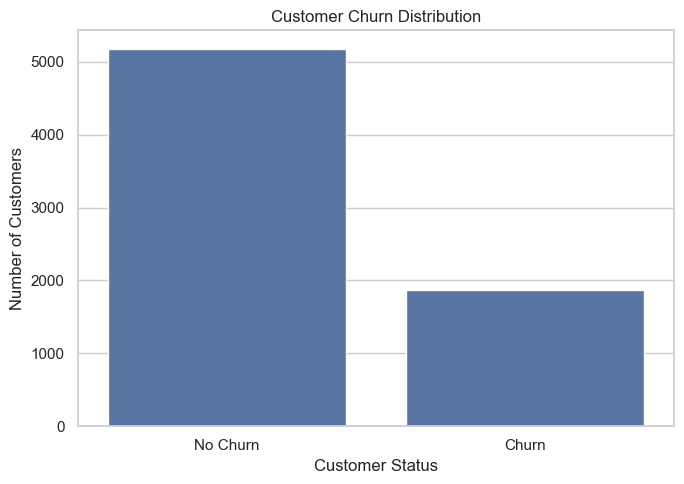

In [8]:
# Visualize the class distribution to understand the proportion of churned and retained customers.
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="Churn")
ax.set_xticklabels(["No Churn", "Churn"])
ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Customer Status")
ax.set_ylabel("Number of Customers")
plt.tight_layout()
plt.savefig(output_dir / "eda_churn_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


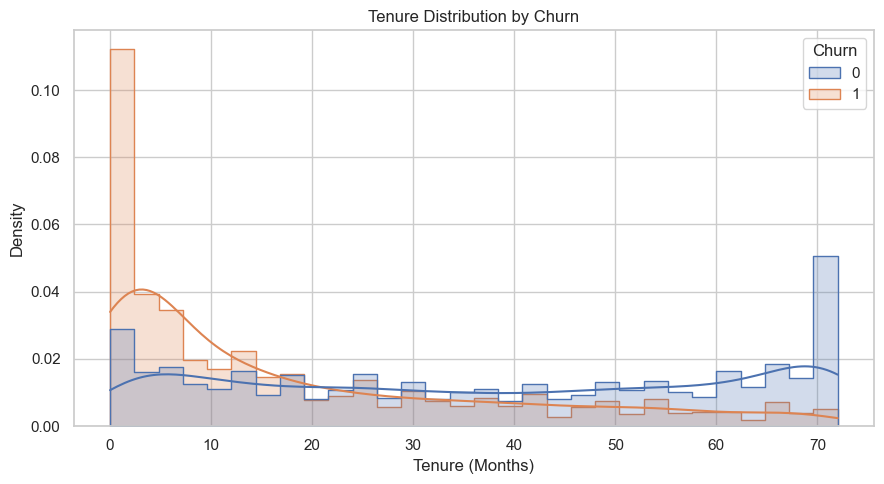

In [9]:
# Compare tenure distributions for churned and non-churned customers to identify behavioral differences.
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, element="step", stat="density", common_norm=False)
plt.title("Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Density")
plt.tight_layout()
plt.savefig(output_dir / "eda_tenure_vs_churn.png", dpi=150, bbox_inches="tight")
plt.show()


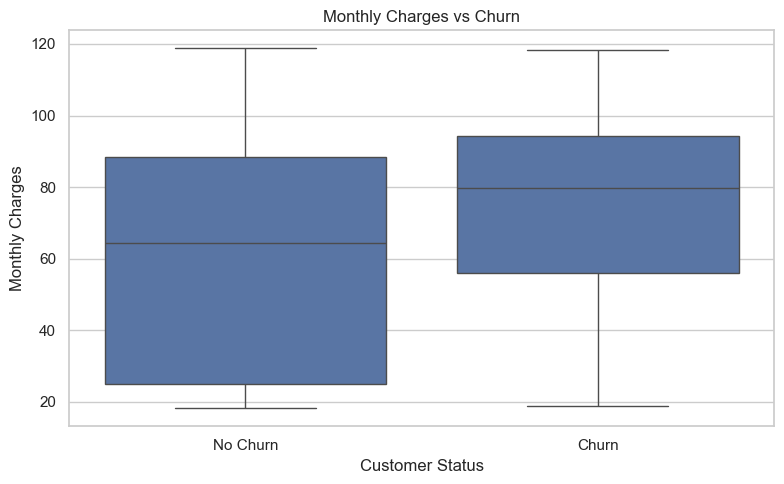

In [10]:
# Compare monthly charges across churn classes to identify whether higher charges are associated with churn.
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.xticks([0, 1], ["No Churn", "Churn"])
plt.title("Monthly Charges vs Churn")
plt.xlabel("Customer Status")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.savefig(output_dir / "eda_monthly_charges_vs_churn.png", dpi=150, bbox_inches="tight")
plt.show()


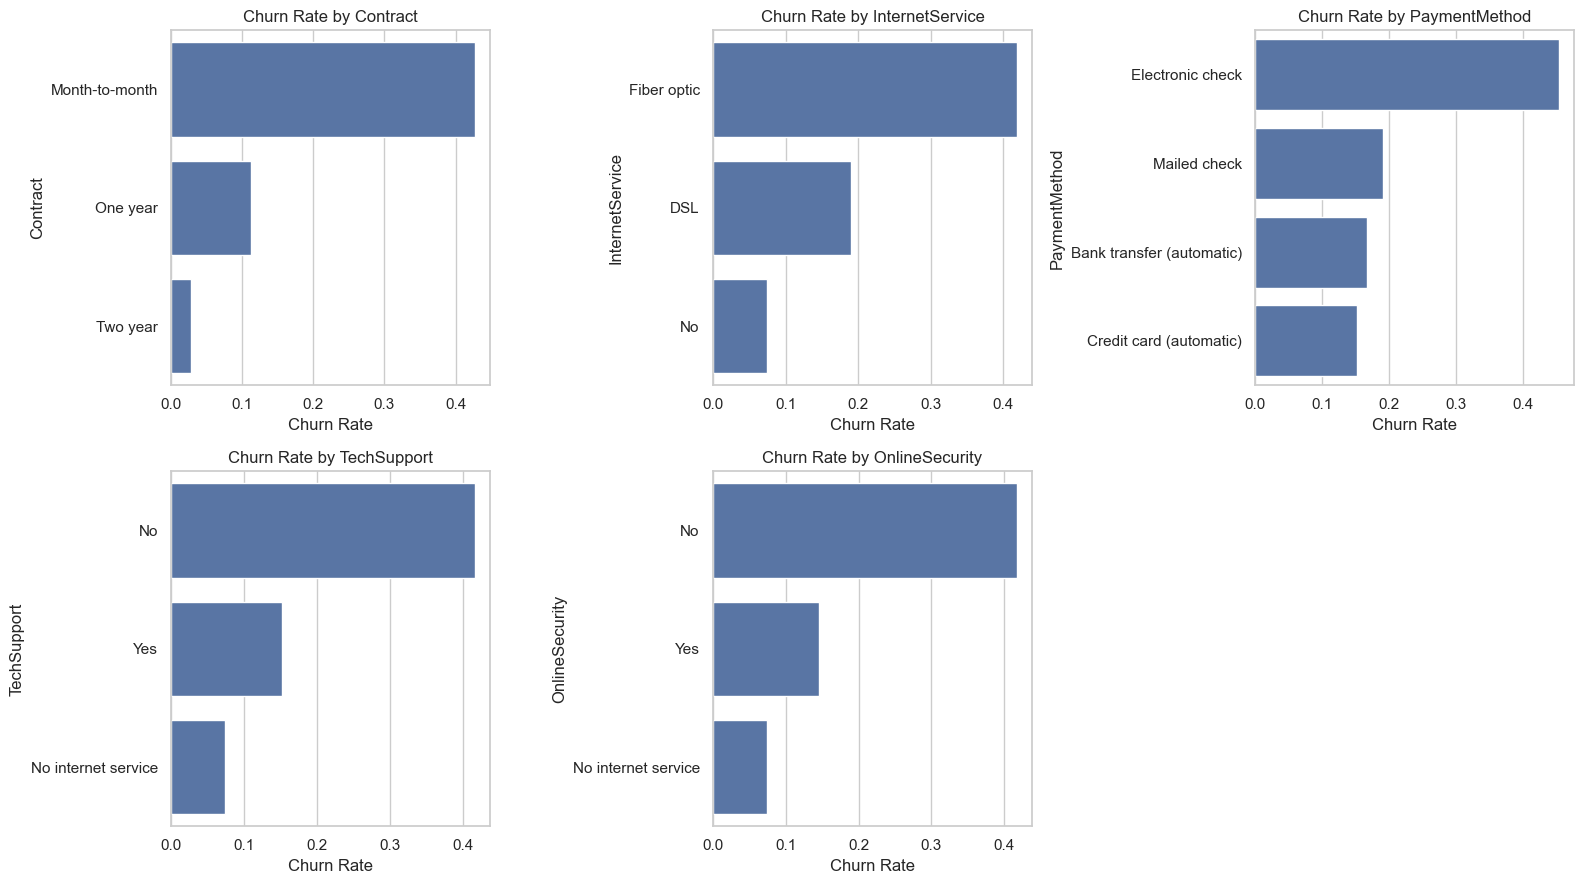

In [11]:
# Analyze churn rates across important categorical business features.
eda_categories = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, eda_categories):
    churn_rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    sns.barplot(x=churn_rate.values, y=churn_rate.index, ax=ax)
    ax.set_title(f"Churn Rate by {col}")
    ax.set_xlabel("Churn Rate")
    ax.set_ylabel(col)

axes[-1].axis("off")
plt.tight_layout()
plt.savefig(output_dir / "eda_categorical_churn_rates.png", dpi=150, bbox_inches="tight")
plt.show()


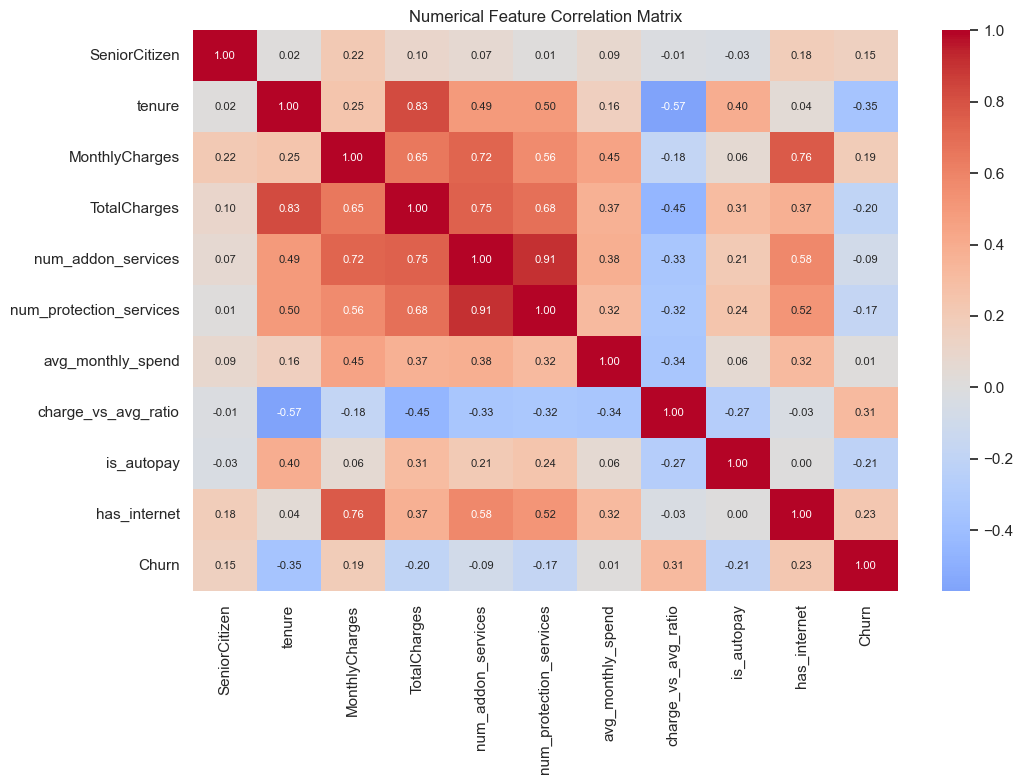

In [12]:
# Display correlations among numerical variables and the target to identify strong linear relationships.
corr = df_fe[numeric_features + ["Churn"]].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="coolwarm", center=0)
plt.title("Numerical Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(output_dir / "eda_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

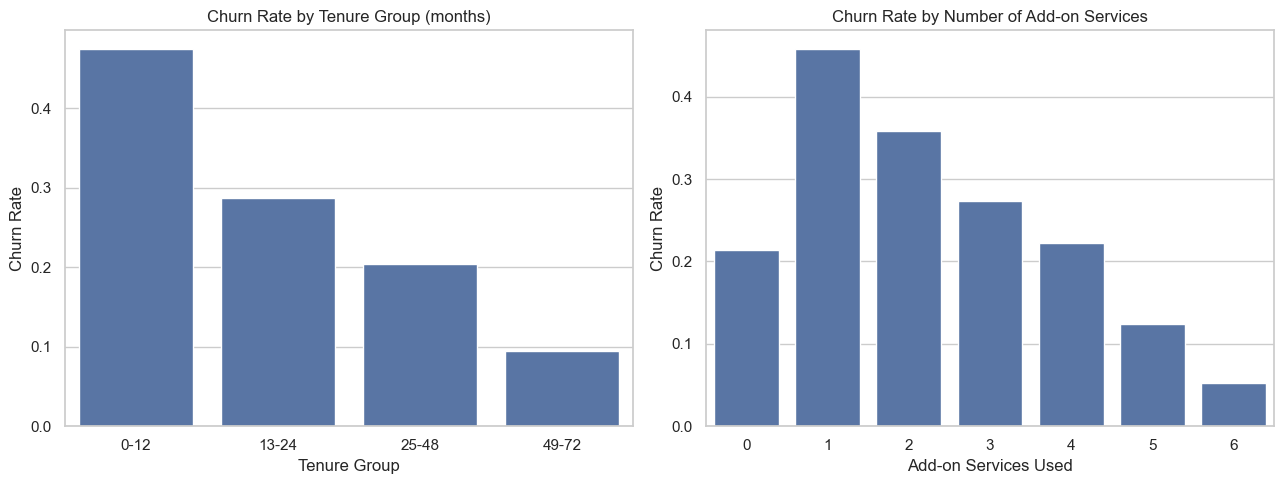

In [13]:
# Show why the engineered features are useful: churn rate by tenure group and by number of add-on services.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

order = ["0-12", "13-24", "25-48", "49-72"]
tg = df_fe.groupby("tenure_group")["Churn"].mean().reindex(order)
sns.barplot(x=tg.index, y=tg.values, ax=axes[0])
axes[0].set_title("Churn Rate by Tenure Group (months)")
axes[0].set_xlabel("Tenure Group")
axes[0].set_ylabel("Churn Rate")

ns = df_fe.groupby("num_addon_services")["Churn"].mean()
sns.barplot(x=ns.index, y=ns.values, ax=axes[1])
axes[1].set_title("Churn Rate by Number of Add-on Services")
axes[1].set_xlabel("Add-on Services Used")
axes[1].set_ylabel("Churn Rate")

plt.tight_layout()
plt.savefig(output_dir / "eda_engineered_features.png", dpi=150, bbox_inches="tight")
plt.show()

# Part 7 — Train/Test Split and Feature Preprocessing

In [14]:
# Split the data into training and test sets while preserving the churn ratio in both subsets.
# The test set is NEVER balanced or used for feature selection - it must stay realistic.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 3))
print("Test churn rate:", round(y_test.mean(), 3))

Training shape: (5634, 19)
Test shape: (1409, 19)
Train churn rate: 0.265
Test churn rate: 0.265


# Part 7B — Feature Selection

Features are scored with **Mutual Information** against the target using the **training set only** (to avoid data leakage).
Features with almost no information about churn are removed so the models learn from signal instead of noise.

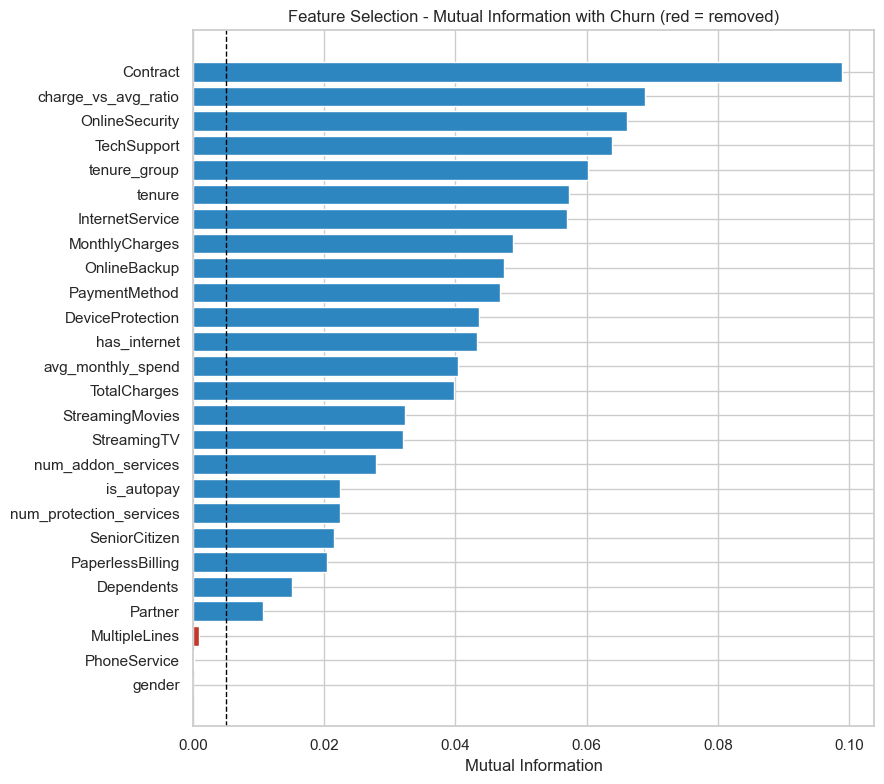

Removed weak features: ['MultipleLines', 'PhoneService', 'gender']
Final numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_addon_services', 'num_protection_services', 'avg_monthly_spend', 'charge_vs_avg_ratio', 'is_autopay', 'has_internet']
Final categorical features: ['Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']


In [15]:
# Score every feature (original + engineered) by how much information it carries about Churn.
X_train_fe = add_features(X_train)

mi_input = X_train_fe.copy()
for col in categorical_features:
    mi_input[col] = mi_input[col].astype("category").cat.codes

discrete_mask = [col in categorical_features for col in mi_input.columns]
mi_scores = pd.Series(
    mutual_info_classif(mi_input, y_train, discrete_features=discrete_mask, random_state=42),
    index=mi_input.columns
).sort_values(ascending=False)

# Remove features that are almost independent from the target.
MI_THRESHOLD = 0.005
weak_features = mi_scores[mi_scores < MI_THRESHOLD].index.tolist()

plt.figure(figsize=(9, 8))
colors = ["#c0392b" if f in weak_features else "#2e86c1" for f in mi_scores.index]
plt.barh(mi_scores.index[::-1], mi_scores.values[::-1], color=colors[::-1])
plt.axvline(MI_THRESHOLD, color="black", linestyle="--", linewidth=1)
plt.title("Feature Selection - Mutual Information with Churn (red = removed)")
plt.xlabel("Mutual Information")
plt.tight_layout()
plt.savefig(output_dir / "eda_feature_importance_mi.png", dpi=150, bbox_inches="tight")
plt.show()

# Keep only the useful features.
numeric_features = [c for c in numeric_features if c not in weak_features]
categorical_features = [c for c in categorical_features if c not in weak_features]

print("Removed weak features:", weak_features)
print("Final numeric features:", numeric_features)
print("Final categorical features:", categorical_features)

In [16]:
# Build the full preprocessing pipeline:
# 1) add_features creates the engineered columns from raw customer data,
# 2) StandardScaler scales the numerical features,
# 3) OneHotEncoder converts categorical features into binary columns,
# 4) remainder="drop" removes the weak features selected above.
preprocessor = Pipeline([
    ("feature_engineering", FunctionTransformer(add_features)),
    ("encode_and_scale", ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_features),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
        ],
        remainder="drop"
    ))
])

X_train_encoded = preprocessor.fit_transform(X_train)
print("Features fed to the models after encoding:", X_train_encoded.shape[1])

Features fed to the models after encoding: 48


# Part 7C — Handling Class Imbalance (SMOTE)

The churn target is imbalanced (about 73% No Churn vs 27% Churn), so models tend to favour the majority class and miss real churners.
**SMOTE** creates synthetic Churn samples so both classes have the same size in the **training data only**.
The test set is left untouched so the evaluation reflects real-world performance.

,Before SMOTE,After SMOTE
No Churn,4139,4139
Churn,1495,4139


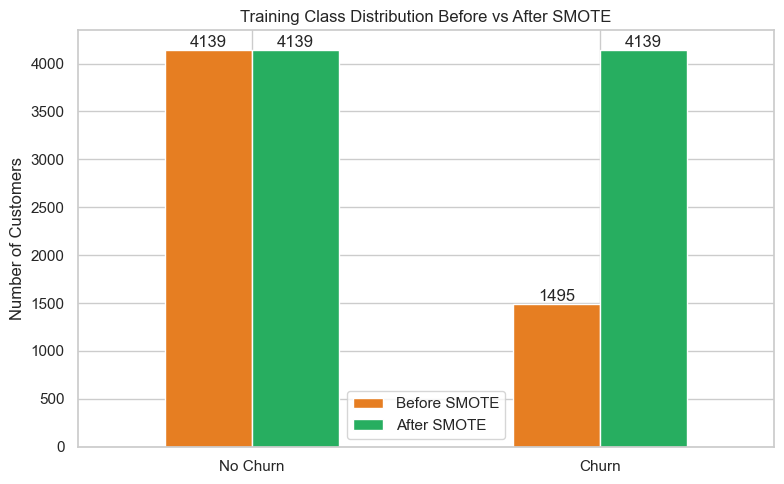

Test set stays unbalanced (real distribution):


Churn
No Churn    1035
Churn        374
Name: count, dtype: int64

In [17]:
# Demonstrate the balancing on the encoded training data (SMOTE is applied only to training data).
smote_demo = SMOTE(random_state=42)
X_demo_balanced, y_demo_balanced = smote_demo.fit_resample(X_train_encoded, y_train)

before_counts = y_train.value_counts().sort_index()
after_counts = pd.Series(y_demo_balanced).value_counts().sort_index()

balance_df = pd.DataFrame({
    "Before SMOTE": before_counts.values,
    "After SMOTE": after_counts.values
}, index=["No Churn", "Churn"])
display(balance_df)

ax = balance_df.plot(kind="bar", figsize=(8, 5), rot=0, color=["#e67e22", "#27ae60"])
ax.set_title("Training Class Distribution Before vs After SMOTE")
ax.set_ylabel("Number of Customers")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig(output_dir / "eda_class_balance_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

print("Test set stays unbalanced (real distribution):")
display(y_test.value_counts().rename(index={0: "No Churn", 1: "Churn"}))

# Part 8 — Machine Learning Models

In [18]:
# Define five supervised ML models required by the project.
models = {
    "KNN": KNeighborsClassifier(n_neighbors=11),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=10, random_state=42, n_jobs=-1
    ),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "Naive Bayes": GaussianNB()
}

print("Models:", list(models.keys()))


Models: ['KNN', 'Decision Tree', 'Random Forest', 'SVM', 'Naive Bayes']


In [19]:
# Train every ML model with: preprocessing -> SMOTE (balances ONLY the training data) -> model.
# At prediction time SMOTE is skipped automatically, and evaluation uses the untouched, real test set.
ml_pipelines = {}
ml_predictions = {}
ml_probabilities = {}
ml_rows = []

for name, estimator in models.items():
    # imblearn does not allow a Pipeline nested inside a Pipeline, so the preprocessing steps are unpacked.
    pipeline = ImbPipeline([
        *preprocessor.steps,
        ("smote", SMOTE(random_state=42)),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    proba = pipeline.predict_proba(X_test)[:, 1]

    ml_pipelines[name] = pipeline
    ml_predictions[name] = pred
    ml_probabilities[name] = proba

    ml_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

ml_results = pd.DataFrame(ml_rows).sort_values("F1-Score", ascending=False).reset_index(drop=True)
display(ml_results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.7665,0.5482,0.6845,0.6088,0.8382
1,SVM,0.7424,0.5101,0.7460,0.6059,0.8150
2,Decision Tree,0.7587,0.5351,0.6925,0.6037,0.8290
3,Naive Bayes,0.7033,0.4665,0.8182,0.5942,0.8175
4,KNN,0.6920,0.4537,0.7861,0.5753,0.8010


# Part 9 — Deep Learning: Data Preparation

In [20]:
# Fit the same preprocessing transformer only on the training data, then transform train and test data.
X_train_processed = preprocessor.fit_transform(X_train).astype("float32")
X_test_processed = preprocessor.transform(X_test).astype("float32")

# Create a validation split from the training data for neural-network monitoring.
X_dl_train, X_val, y_dl_train, y_val = train_test_split(
    X_train_processed, y_train.to_numpy(),
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Balance ONLY the DL training part with SMOTE. The validation and test sets keep the real class distribution.
print("DL train class counts before SMOTE:", dict(zip(*np.unique(y_dl_train, return_counts=True))))
X_dl_train, y_dl_train = SMOTE(random_state=42).fit_resample(X_dl_train, y_dl_train)
print("DL train class counts after SMOTE:", dict(zip(*np.unique(y_dl_train, return_counts=True))))

X_dl_train = X_dl_train.astype("float32")
y_dl_train = y_dl_train.astype("float32")
y_val = y_val.astype("float32")
y_test_dl = y_test.to_numpy().astype("float32")

print("DL Train:", X_dl_train.shape)
print("DL Validation:", X_val.shape)
print("DL Test:", X_test_processed.shape)

DL train class counts before SMOTE: {np.int64(0): np.int64(3311), np.int64(1): np.int64(1196)}
DL train class counts after SMOTE: {np.int64(0): np.int64(3311), np.int64(1): np.int64(3311)}
DL Train: (6622, 48)
DL Validation: (1127, 48)
DL Test: (1409, 48)


# Part 10 — Deep Learning: Neural Network

In [21]:
# Build a feed-forward neural network with dropout and batch normalization for binary churn classification.
dl_model = keras.Sequential([
    layers.Input(shape=(X_dl_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.30),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

dl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

dl_model.summary()
print("Training data is balanced with SMOTE, so no class weights are needed.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,017 (23.50 KB)

 Trainable params: 5,889 (23.00 KB)

 Non-trainable params: 128 (512.00 B)

Training data is balanced with SMOTE, so no class weights are needed.


# Part 11 — Deep Learning: Training and Validation

In [22]:
# Train the neural network and stop early when validation loss no longer improves.
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = dl_model.fit(
    X_dl_train, y_dl_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

print("Training epochs:", len(history.history["loss"]))

Training epochs: 13


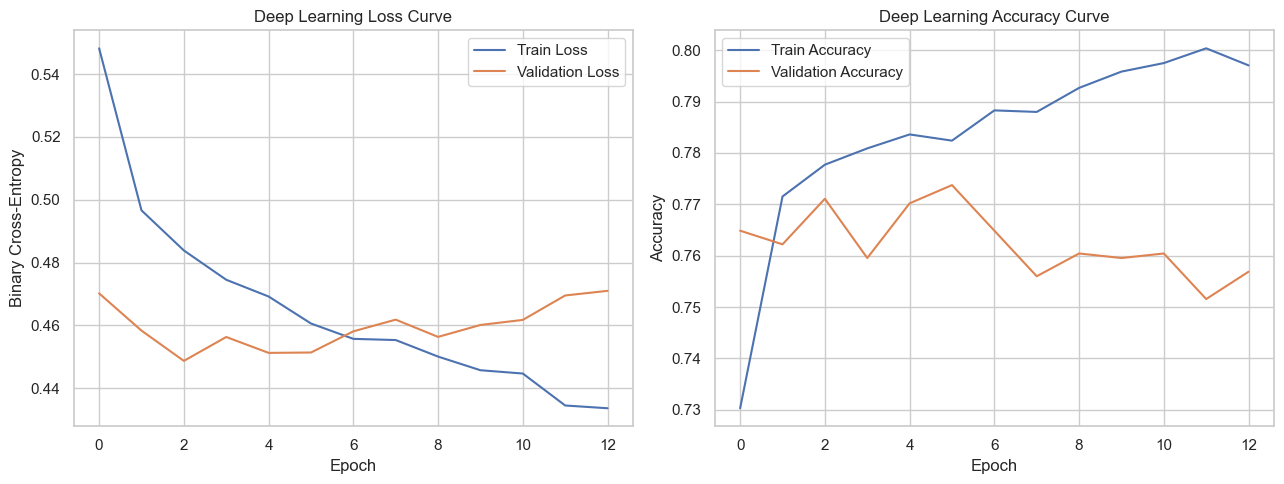

In [23]:
# Plot the required training/validation loss and accuracy curves to diagnose learning behavior and overfitting.
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history_df["loss"], label="Train Loss")
axes[0].plot(history_df["val_loss"], label="Validation Loss")
axes[0].set_title("Deep Learning Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy")
axes[0].legend()

axes[1].plot(history_df["accuracy"], label="Train Accuracy")
axes[1].plot(history_df["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Deep Learning Accuracy Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig(output_dir / "dl_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()


# Part 12 — Evaluation and Model Comparison

In [24]:
# Evaluate the trained neural network on the untouched test set using the same metrics as the ML models.
dl_probability = dl_model.predict(X_test_processed, verbose=0).ravel()
dl_prediction = (dl_probability >= 0.50).astype(int)

dl_row = {
    "Model": "Deep Learning",
    "Accuracy": accuracy_score(y_test, dl_prediction),
    "Precision": precision_score(y_test, dl_prediction, zero_division=0),
    "Recall": recall_score(y_test, dl_prediction, zero_division=0),
    "F1-Score": f1_score(y_test, dl_prediction, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, dl_probability)
}

all_predictions = dict(ml_predictions)
all_probabilities = dict(ml_probabilities)
all_predictions["Deep Learning"] = dl_prediction
all_probabilities["Deep Learning"] = dl_probability

comparison = pd.concat(
    [ml_results, pd.DataFrame([dl_row])],
    ignore_index=True
).sort_values("F1-Score", ascending=False).reset_index(drop=True)

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Deep Learning,0.7537,0.5243,0.7781,0.6265,0.8423
1,Random Forest,0.7665,0.5482,0.6845,0.6088,0.8382
2,SVM,0.7424,0.5101,0.7460,0.6059,0.8150
3,Decision Tree,0.7587,0.5351,0.6925,0.6037,0.8290
4,Naive Bayes,0.7033,0.4665,0.8182,0.5942,0.8175
5,KNN,0.6920,0.4537,0.7861,0.5753,0.8010


In [25]:
# Print detailed classification reports for every model so precision, recall, and F1 are transparent by class.
for name, pred in all_predictions.items():
    print("=" * 70)
    print(name)
    print(classification_report(
        y_test, pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))


KNN
              precision    recall  f1-score   support

    No Churn       0.89      0.66      0.76      1035
       Churn       0.45      0.79      0.58       374

    accuracy                           0.69      1409
   macro avg       0.67      0.72      0.67      1409
weighted avg       0.78      0.69      0.71      1409

Decision Tree
              precision    recall  f1-score   support

    No Churn       0.88      0.78      0.83      1035
       Churn       0.54      0.69      0.60       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409

Random Forest
              precision    recall  f1-score   support

    No Churn       0.87      0.80      0.83      1035
       Churn       0.55      0.68      0.61       374

    accuracy                           0.77      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.77      0.7

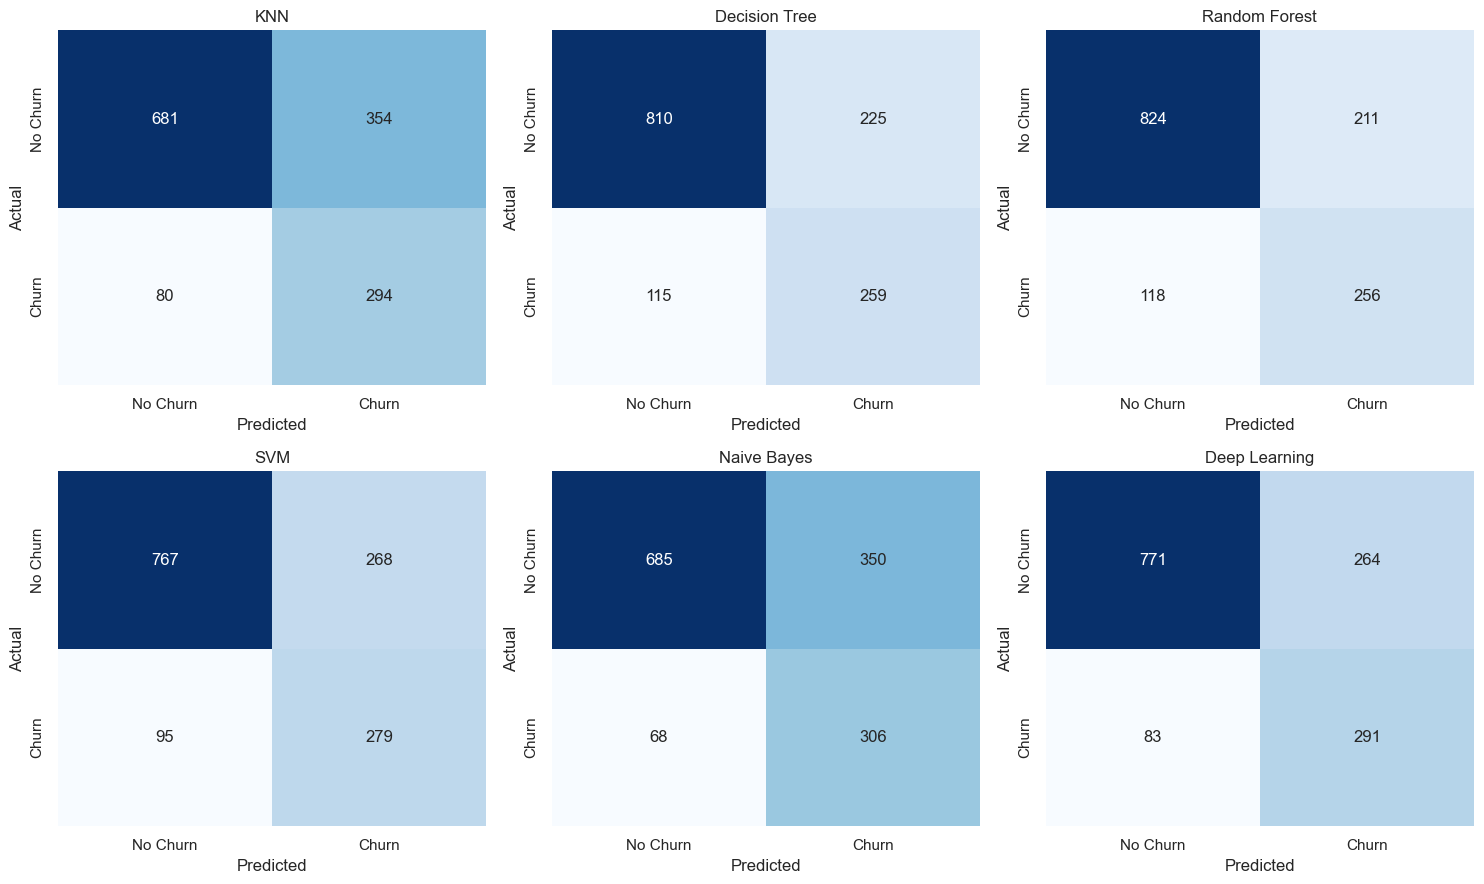

In [26]:
# Visualize confusion matrices for all ML and Deep Learning models.
n_models = len(all_predictions)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4.5 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, (name, pred) in zip(axes, all_predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(output_dir / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()


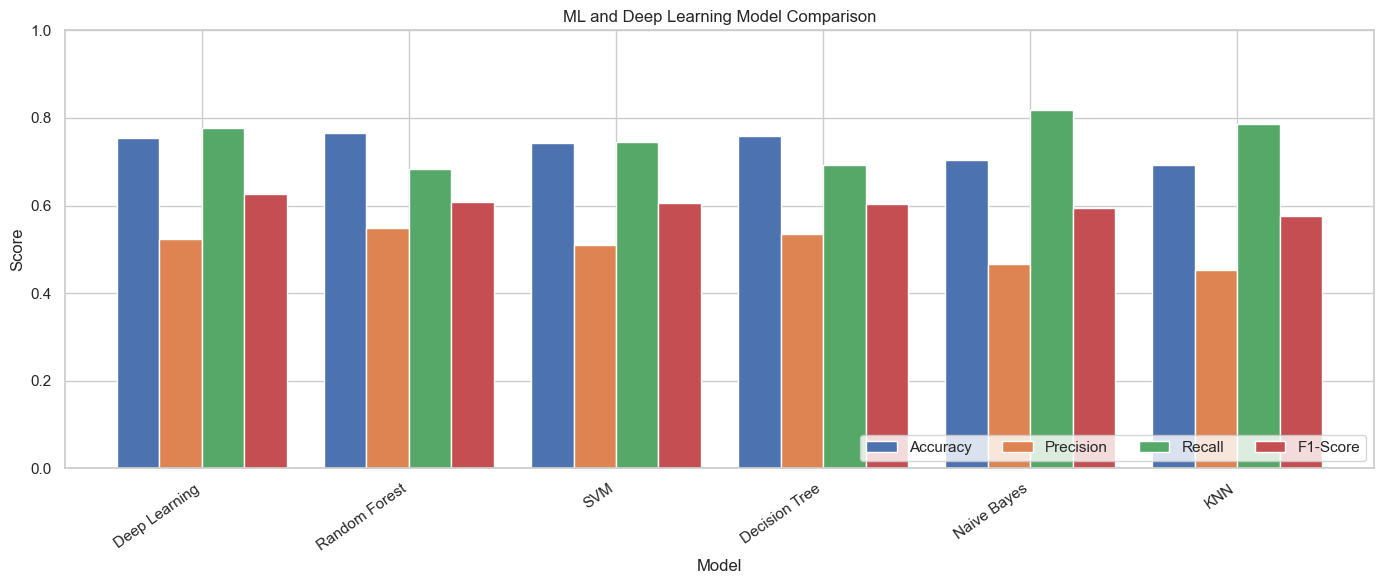

In [27]:
# Compare Accuracy, Precision, Recall, and F1-Score across every model.
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

comparison_plot = comparison.set_index("Model")[metrics]
ax = comparison_plot.plot(kind="bar", figsize=(14, 6), ylim=(0, 1), width=0.82)
ax.set_title("ML and Deep Learning Model Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right", ncol=4)
plt.tight_layout()
plt.savefig(output_dir / "metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


In [28]:
# Select the best model based on F1-Score because churn detection should balance precision and recall.
best_model_name = comparison.iloc[0]["Model"]
best_f1 = comparison.iloc[0]["F1-Score"]

print(f"Best model based on F1-Score: {best_model_name}")
print(f"Best F1-Score: {best_f1:.4f}")

# Explain the selection using the class-imbalance context.
print(
    "F1-Score was used as the primary selection criterion because it balances "
    "false positives and false negatives instead of relying on accuracy alone."
)


Best model based on F1-Score: Deep Learning
Best F1-Score: 0.6265
F1-Score was used as the primary selection criterion because it balances false positives and false negatives instead of relying on accuracy alone.


# Part 13 — Final Prediction for a New Customer

In [29]:
# Create a realistic example customer and predict Churn/No Churn with a probability.
new_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "DSL",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 70.0,
    "TotalCharges": 140.0
}])

# Predict with the best ML model when the selected winner is an ML model; otherwise use the neural network.
if best_model_name != "Deep Learning":
    final_probability = ml_pipelines[best_model_name].predict_proba(new_customer)[:, 1][0]
else:
    new_customer_processed = preprocessor.transform(new_customer).astype("float32")
    final_probability = float(dl_model.predict(new_customer_processed, verbose=0).ravel()[0])

final_label = "Churn" if final_probability >= 0.50 else "No Churn"

print("Prediction:", final_label)
print(f"Churn Probability: {final_probability:.2%}")
display(new_customer)


Prediction: Churn
Churn Probability: 73.91%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,No,No,2,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.0,140.0


# Part 14 — Save Models, Results, and Visualizations

In [30]:
# Save the preprocessing transformer, ML pipelines, neural network, and comparison table for the Streamlit application.
joblib.dump(preprocessor, models_dir / "preprocessor.joblib")

for name, pipeline in ml_pipelines.items():
    safe_name = name.lower().replace(" ", "_")
    joblib.dump(pipeline, models_dir / f"{safe_name}.joblib")

dl_model.save(models_dir / "deep_learning_model.keras")
comparison.to_csv(output_dir / "model_comparison.csv", index=False)

# Save the model-selection information so the Streamlit app can use the same best model.
selection_info = {
    "best_model": best_model_name,
    "selection_metric": "F1-Score",
    "best_f1": float(best_f1),
    "removed_features": weak_features,
    "balancing": "SMOTE (training data only)"
}
joblib.dump(selection_info, models_dir / "model_selection.joblib")

print("Saved model artifacts to:", models_dir)
print("Saved results/visualizations to:", output_dir)

Saved model artifacts to: d:\customer_churn_project_final\customer_churn_project_final\models
Saved results/visualizations to: d:\customer_churn_project_final\customer_churn_project_final\outputs


# Part 15 — Requirements Checklist

In [31]:
# Verify that every requested project component has been implemented in the notebook.
requirements_check = {
    "Missing values handled": df.isna().sum().sum() == 0,
    "Encoding applied": len(categorical_features) > 0,
    "Feature scaling applied": True,
    "Feature engineering applied": all(f in X_engineered.columns for f in engineered_numeric_features),
    "Weak features removed": all(f not in numeric_features + categorical_features for f in weak_features),
    "Class imbalance handled (SMOTE)": pd.Series(y_demo_balanced).value_counts().nunique() == 1,
    "Train/Test split": len(X_train) > 0 and len(X_test) > 0,
    "EDA completed": all(
        (output_dir / f).exists() for f in [
            "eda_churn_distribution.png",
            "eda_tenure_vs_churn.png",
            "eda_monthly_charges_vs_churn.png",
            "eda_categorical_churn_rates.png",
            "eda_correlation_heatmap.png"
        ]
    ),
    "At least 3 ML models": len(models) >= 3,
    "Deep Learning model": dl_model is not None,
    "Training & Validation": len(history.history["loss"]) > 0,
    "Loss & Accuracy curves": (output_dir / "dl_training_curves.png").exists(),
    "Accuracy metric": "Accuracy" in comparison.columns,
    "Precision metric": "Precision" in comparison.columns,
    "Recall metric": "Recall" in comparison.columns,
    "F1-Score metric": "F1-Score" in comparison.columns,
    "Confusion matrices": (output_dir / "confusion_matrices.png").exists(),
    "Model comparison": (output_dir / "model_comparison.csv").exists(),
    "Final prediction + probability": final_label in {"Churn", "No Churn"} and 0 <= final_probability <= 1,
}

check_df = pd.DataFrame(
    [{"Requirement": k, "Status": "PASS" if v else "FAIL"} for k, v in requirements_check.items()]
)

display(check_df)

if not all(requirements_check.values()):
    raise AssertionError("One or more project requirements are not satisfied.")
else:
    print("All project requirements are satisfied.")

,Requirement,Status
0,Missing values handled,PASS
1,Encoding applied,PASS
2,Feature scaling applied,PASS
3,Feature engineering applied,PASS
4,Weak features removed,PASS
5,Class imbalance handled (SMOTE),PASS
6,Train/Test split,PASS
7,EDA completed,PASS
8,At least 3 ML models,PASS
9,Deep Learning model,PASS


All project requirements are satisfied.
